# NGC 1068 GTI: median Poisson detection significance versus flux

This self-contained notebook repeats the binned flux-sensitivity calculation
using **100 Poisson realizations at each of 100 flux points**, for cutoff
energies of **400 and 128 keV**. The CPL photon index is $\Gamma=2.1$
(`index = -2.1` in astromodels):

$$\frac{\mathrm{d}N}{\mathrm{d}E}=K\left(\frac{E}{200\,\mathrm{keV}}\right)^{-2.1}
\exp\!\left(-\frac{E}{E_c}\right).$$

The 128-keV injected spectral shape matches the thermal CPL in the NGC 1068
Case 1 sensitivity notebook; its normalization is scanned here. The 400-keV
case is a comparison spectrum. Position, index, and cutoff remain fixed in
these fits. The Case 1 sensitivity notebook allows spectral parameters to vary,
so its ensemble statistics need not match this fixed-shape calculation.

Run all cells from top to bottom with `cosipy312`. All functions are defined
here; no other notebook or local analysis helper is imported.

- **Exposure:** repeat the NGC 1068 three-month, 60-degree GTI eight times by
  multiplying orientation livetimes, source expectation, and background
  expectation consistently for 24 months.
- **Flux:** integrated energy flux over 100-1,000 keV, from $10^{-12}$ to
  $10^{-8}$ erg cm$^{-2}$ s$^{-1}$ in 100 logarithmically spaced points.
- **Likelihood:** retain the full binned measured-energy/Compton data space;
  exclude zero-raw-background cells from both source and background.
- **Simulation:** generate Poisson source-plus-background counts. Fit a
  nonnegative source amplitude and one free background normalization for each
  realization. Individual count cubes are held only in memory.
- **Summary:** retain the median TS at each injected flux. The plotted nominal
  detection significance is $\sqrt{\mathrm{median}(\mathrm{TS})}$.
- **Files:** one energy-flux CSV per cutoff, with exactly `energy_flux_erg_cm2_s` and `ts`
  (100 median values), plus two individual PDFs and one overlay PDF. No
  individual realizations, PNG exports, or JSON sidecars are saved.

Additional photon-flux figures express the same results as the integrated
number of photons over 100-1,000 keV. Each photon-flux CSV contains only
`photon_flux_ph_cm2_s` and `ts`. Photon and energy fluxes are obtained by
integrating the same fixed CPL shape; the TS values are unchanged.


In [1]:
from pathlib import Path
import hashlib
import time

import astropy.units as u
from astropy.coordinates import SkyCoord
from astromodels import Cutoff_powerlaw, Model, PointSource
from histpy import Histogram
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.integrate import quad
from scipy.optimize import brentq

from cosipy import SpacecraftHistory, SourceInjector
from cosipy.event_selection import GoodTimeInterval

%matplotlib inline


No event loop hook running.


13:36:18 WARNING   The naima package is not available. Models    functions.py:43
                  that depend on it will not be available                       
         WARNING   The GSL library or the pygsl wrapper cannot   functions.py:65
                  be loaded. Models that depend on it will not                  
                  be available.                                                 
13:36:19 WARNING   The ebltable package is not available.       absorption.py:33
                  Models that depend on it will not be                          
                  available                                                     
13:36:20 INFO      Starting 3ML!                                  __init__.py:44
         WARNING   WARNINGs here are NOT errors                   __init__.py:45
         WARNING   but are inform you about optional packages     __init__.py:46
                  that can be installed                                         
         WARNING    to disab

## 1. Inputs, flux grid, and ensemble size

`N_REALIZATIONS` sets the number of draws at each flux. `BASE_SEED` determines
reproducible independent streams for each cutoff, flux index, and realization
index. The same exposure, event selection, and spectral settings are used as
in the companion Asimov notebook.

Completed flux points are checkpointed in the median-only CSV. With
`RESUME_EXISTING=True`, rerunning resumes after the last completed point.
Output names include a short signature of the actual source/background
templates and run settings, so a different model or ensemble cannot reuse a
stale checkpoint. No metadata sidecar is needed.

**Flux integration band:** 100-1,000 keV for both energy and photon flux.
The detection likelihood still uses the original 100-10,000 keV measured-energy
range. The CPL is folded through the full response without truncation at
1,000 keV. The grid and reference flux are normalized to the reporting band;
changing this band therefore changes the source amplitude at a fixed grid
value. Output filenames include the flux-band limits.


In [2]:
NOTEBOOK_DIR = Path('/Users/parshadkp/Software/cosipy/docs/tutorials/source_injector')
DATA_DIR = Path(
    '/Users/parshadkp/Library/CloudStorage/OneDrive-ClemsonUniversity/'
    'COSI/Radio_Quiet_AGN/DC4_Files'
)
RESPONSE_PATH = DATA_DIR / (
    'ResponseContinuum.o3.e100_10000.b10log.s10396905069491.m2284.'
    'filtered.nonsparse.binnedimaging.imagingresponse.h5'
)
ORIENTATION_PATH = DATA_DIR / 'DC4_final_530km_3_month_with_slew_15sbins_GalacticEarth_SAA.fits'
BACKGROUND_PATH = DATA_DIR / 'Background' / (
    'Total_DC4_BG_3months_binned_data_filtered_with_SAAcut_withSAAbck_'
    'NGC1068_60deg_fov_cut.hdf5'
)
OUTPUT_ROOT = NOTEBOOK_DIR / 'outputs'
BASE_EXPOSURE_MONTHS = 3
EXPOSURE_MONTHS = 24
EXPOSURE_MULTIPLIER = EXPOSURE_MONTHS / BASE_EXPOSURE_MONTHS

LONGITUDE_DEG, LATITUDE_DEG = 172.104, -51.934
FOV_CUT = 60.0 * u.deg
SPECTRAL_INDEX = -2.1
SPECTRAL_INDEX_TAG = f'{SPECTRAL_INDEX:g}'.replace('-', 'm').replace('.', 'p')
PIVOT_KEV = 200.0
FLUX_BAND_KEV = (100.0, 1000.0)
FLUX_BAND_TAG = f'band{FLUX_BAND_KEV[0]:g}_{FLUX_BAND_KEV[1]:g}keV' 
N_FLUX_POINTS = 100
FLUX_POINTS = np.geomspace(1e-12, 1e-8, N_FLUX_POINTS) * u.erg / (u.cm**2 * u.s)
REFERENCE_FLUX = 1e-10 * u.erg / (u.cm**2 * u.s)
PROFILE_BACKGROUND = True
N_REALIZATIONS = 100
BASE_SEED = 106800
RESUME_EXISTING = True
FIT_METHOD_VERSION = 'fixed_shape_poisson_mixture_v1'
if not isinstance(N_REALIZATIONS, int) or N_REALIZATIONS < 1:
    raise ValueError('N_REALIZATIONS must be a positive integer.')

if not np.isfinite(EXPOSURE_MULTIPLIER) or EXPOSURE_MULTIPLIER <= 0:
    raise ValueError('The exposure multiplier must be positive and finite.')
for path in (RESPONSE_PATH, ORIENTATION_PATH, BACKGROUND_PATH):
    if not path.is_file():
        raise FileNotFoundError(path)
if not 0 < FLUX_BAND_KEV[0] < FLUX_BAND_KEV[1]:
    raise ValueError('The integrated-flux energy band must be positive and increasing.')
flux_values = FLUX_POINTS.to_value(u.erg / (u.cm**2 * u.s))
if flux_values.ndim != 1 or len(flux_values) < 2 or not np.all(np.isfinite(flux_values)):
    raise ValueError('Supply at least two finite flux points.')
if np.any(flux_values <= 0) or np.any(np.diff(flux_values) <= 0):
    raise ValueError('Flux points must be positive and strictly increasing.')
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)


## 2. Select the GTI and scale the exposure

The pointing GTI has `earth_occ=False`, matching the reference NGC 1068 setup.
The source response later uses `earth_occ=True`. Scaling interval livetimes
preserves the sampled geometry and multiplies the source expectation by eight.
The matching three-month background is also multiplied by eight. Intrinsic
source flux is unchanged by this exposure scaling.


In [3]:
source_coord = SkyCoord(l=LONGITUDE_DEG, b=LATITUDE_DEG, unit='deg', frame='galactic')
full_orientation = SpacecraftHistory.open(ORIENTATION_PATH)
source_gti = GoodTimeInterval.from_pointing_cut(
    source_coord, full_orientation, FOV_CUT, earth_occ=False,
)
orientation_gti_3m = full_orientation.apply_gti(source_gti)
base_livetime_s = float(orientation_gti_3m.cumulative_livetime().to_value(u.s))
orientation_gti = SpacecraftHistory(
    orientation_gti_3m.obstime,
    orientation_gti_3m.attitude,
    orientation_gti_3m.location,
    livetime=orientation_gti_3m.livetime * EXPOSURE_MULTIPLIER,
)
orientation_gti.cache_earth_occ = orientation_gti_3m.cache_earth_occ
livetime_s = float(orientation_gti.cumulative_livetime().to_value(u.s))
np.testing.assert_allclose(livetime_s, base_livetime_s * EXPOSURE_MULTIPLIER)
if len(source_gti) == 0 or livetime_s <= 0:
    raise ValueError('The pointing cut selected no usable exposure.')
print(f'GTI intervals: {len(source_gti):,}')
print(f'Selected three-month livetime: {base_livetime_s:,.1f} s')
print(f'Exposure multiplier: {EXPOSURE_MULTIPLIER:g}')
print(f'Scaled {EXPOSURE_MONTHS:g}-month livetime: {livetime_s:,.1f} s')

# The same exposure-scaled background is used for both cutoff cases.
background = (
    Histogram.open(BACKGROUND_PATH).project('Em', 'Phi', 'PsiChi')
    * EXPOSURE_MULTIPLIER
)


GTI intervals: 1,300
Selected three-month livetime: 2,546,115.0 s
Exposure multiplier: 8
Scaled 24-month livetime: 20,368,920.0 s


## 3. Likelihood and exact zero-source null

Let $s_i$ be the source expectation at the reference flux and $b_i$ the
background expectation in retained detector cell $i$. At injected flux $F$,

$$n_i\sim\mathrm{Poisson}\!\left[(F/F_{\rm ref})s_i+b_i\right].$$

The fitted expectation is $a s_i+\beta b_i$, with $a\geq0$ and $\beta\geq0$.
The background template is the same for every draw; its event contribution is
already fluctuated in the Poisson draw. The detection statistic is

$$\mathrm{TS}=2\left[\log L(\widehat a,\widehat\beta)
-\log L(0,\widehat\beta_0)\right],\qquad
\widehat\beta_0=\frac{\sum_i n_i}{\sum_i b_i}.$$

If the fitted source amplitude is zero, TS is zero. With fixed position and
spectral shape, $\sqrt{\mathrm{TS}}$ is the nominal asymptotic one-sided local
significance. Source-amplitude and background-normalization fits are repeated
for each realization. The Asimov formula is used only for validation.

For a free background, this two-amplitude problem reduces to one scalar fit.
Write $S=\sum_i s_i$, $B=\sum_i b_i$, $p_i=s_i/S$, $q_i=b_i/B$, and
$a s_i+\beta b_i=T[fp_i+(1-f)q_i]$. The maximum-likelihood total yield is
$\widehat T=N=\sum_i n_i$. Only the source fraction $0\leq f\leq1$ remains.
The log likelihood in $f$ is concave, so its derivative has at most one root.
The null has $f=0$, giving the exact statistic

$$\mathrm{TS}=2\sum_{i:n_i>0} n_i\log\!\left[1+\widehat f\left(p_i/q_i-1\right)\right].$$

This avoids rebuilding a threeML model or folding the response for each draw.
The same likelihood is optimized; no Gaussian approximation to the simulated
counts is used. `PROFILE_BACKGROUND=False` instead fits the source amplitude
with the background held fixed at its generating value.


In [4]:
def histogram_values(histogram):
    values = histogram.contents
    if hasattr(values, 'compute'):
        values = values.compute()
    if hasattr(values, 'todense'):
        values = values.todense()
    if hasattr(values, 'value'):
        values = values.value
    return np.asarray(values, dtype=float)

def poisson_deviance_kernel(ratio):
    # h(r) = (1+r)*log(1+r)-r, with a series near zero.
    ratio = np.asarray(ratio, dtype=float)
    small = ratio < 1e-4
    result = np.empty_like(ratio)
    r = ratio[small]
    result[small] = r*r*(0.5 + r*(-1/6 + r*(1/12 + r*(-1/20 + r/30))))
    r = ratio[~small]
    result[~small] = (1+r)*np.log1p(r)-r
    return result


def asimov_detection_ts(signal, background_counts, *, profile_background=True):
    signal = np.asarray(signal, dtype=float).ravel()
    background_counts = np.asarray(background_counts, dtype=float).ravel()
    if signal.shape != background_counts.shape or signal.size == 0:
        raise ValueError('Signal and background must have matching nonempty shapes.')
    if (not np.all(np.isfinite(signal)) or np.any(signal < 0)
            or not np.all(np.isfinite(background_counts)) or np.any(background_counts <= 0)):
        raise ValueError('Require finite signal >= 0 and background > 0 in every retained cell.')
    signal_total = float(signal.sum())
    background_total = float(background_counts.sum())
    fixed_ts = float(2 * np.sum(
        background_counts * poisson_deviance_kernel(signal / background_counts)
    ))
    null_scale = 1.0
    null_gain = 0.0
    if profile_background:
        total_ratio = signal_total / background_total
        null_scale += total_ratio
        null_gain = float(2 * background_total * poisson_deviance_kernel(total_ratio))
    ts = fixed_ts - null_gain
    if ts < -1e-9 * max(1.0, fixed_ts):
        raise ArithmeticError('Unexpected negative likelihood-ratio TS.')
    return max(0.0, ts), null_scale


In [5]:
class FixedShapePoissonFit:
    """Fit one nonnegative source amplitude and an optional background scale."""

    def __init__(self, source, background_counts, *, profile_background=True):
        self.source = np.asarray(source, dtype=float).ravel()
        self.background = np.asarray(background_counts, dtype=float).ravel()
        if self.source.shape != self.background.shape or not self.source.size:
            raise ValueError('Source and background must have matching nonempty shapes.')
        if (not np.all(np.isfinite(self.source)) or np.any(self.source < 0)
                or not np.all(np.isfinite(self.background)) or np.any(self.background <= 0)):
            raise ValueError('Require source >= 0 and background > 0 in retained cells.')
        self.S = float(self.source.sum())
        self.B = float(self.background.sum())
        if self.S <= 0:
            raise ValueError('The source template has no expected counts.')
        self.profile_background = bool(profile_background)
        self.h = (self.source / self.S) / (self.background / self.B) - 1.0
        self.source_to_background = self.source / self.background

    def fit(self, counts):
        """Return TS, fitted source scale a, and fitted background scale beta."""
        counts = np.asarray(counts, dtype=float).ravel()
        if counts.shape != self.source.shape or not np.all(np.isfinite(counts)) or np.any(counts < 0):
            raise ValueError('Counts must match the templates and be finite and nonnegative.')
        N = float(counts.sum())
        if N == 0:
            return 0.0, 0.0, 0.0 if self.profile_background else 1.0

        if self.profile_background:
            observed = counts > 0
            n = counts[observed]
            h = self.h[observed]

            def score(fraction):
                with np.errstate(divide='ignore'):
                    return float(np.sum(n * h / (1.0 + fraction * h)))

            if score(0.0) <= 0 or np.max(np.abs(h)) < 1e-12:
                return 0.0, 0.0, N / self.B
            if score(1.0) >= 0:
                fraction = 1.0
            else:
                fraction = brentq(score, 0.0, 1.0, xtol=1e-15, rtol=1e-11)
            ts = float(2.0 * np.sum(n * np.log1p(fraction * h)))
            source_scale = N * fraction / self.S
            background_scale = N * (1.0 - fraction) / self.B
        else:
            ratio = self.source_to_background

            def score(source_scale):
                return float(np.sum(counts * ratio / (1.0 + source_scale * ratio)) - self.S)

            if score(0.0) <= 0:
                return 0.0, 0.0, 1.0
            upper = 1.0
            while score(upper) > 0:
                upper *= 2.0
                if upper > 1e12:
                    raise RuntimeError('Could not bracket the source-amplitude maximum.')
            source_scale = brentq(score, 0.0, upper, xtol=1e-12, rtol=1e-10)
            background_scale = 1.0
            ts = float(2.0 * (
                np.sum(counts * np.log1p(source_scale * ratio)) - source_scale * self.S
            ))
        if not np.isfinite(ts) or ts < -1e-6:
            raise ArithmeticError(f'Invalid likelihood-ratio TS: {ts}')
        return max(0.0, ts), source_scale, background_scale


## 4. Fold each source template once

Normalize each cutoff spectrum to the same reference energy flux and fold it
through the scaled orientation. Apply the same positive-background mask as the
Asimov calculation, reporting both the retained source counts and retained
fraction. All trial fluxes scale this fixed source template linearly.


In [6]:
def prepare_cutoff_case(cutoff_keV):
    """Fold a reference CPL spectrum and select supported detector cells."""
    cutoff_keV = float(cutoff_keV)
    if not np.isfinite(cutoff_keV) or cutoff_keV <= 0:
        raise ValueError('Cutoff energy must be positive and finite.')
    print(f'Cutoff: {cutoff_keV:g} keV; exposure: {EXPOSURE_MONTHS:g} months')
    energy_min, energy_max = map(float, FLUX_BAND_KEV)

    def unit_k_shape(energy_keV):
        return (energy_keV / PIVOT_KEV)**SPECTRAL_INDEX * np.exp(-energy_keV / cutoff_keV)

    energy_flux_per_k = quad(
        lambda energy: energy * unit_k_shape(energy), energy_min, energy_max,
        epsabs=0.0, epsrel=1e-10,
    )[0] * u.keV.to(u.erg)
    photon_flux_per_k = quad(
        unit_k_shape, energy_min, energy_max, epsabs=0.0, epsrel=1e-10,
    )[0]
    reference_flux_value = REFERENCE_FLUX.to_value(u.erg / (u.cm**2 * u.s))
    if not np.isfinite(reference_flux_value) or reference_flux_value <= 0:
        raise ValueError('REFERENCE_FLUX must be positive and finite.')
    reference_k = reference_flux_value / energy_flux_per_k

    spectrum = Cutoff_powerlaw()
    spectrum.K.value = reference_k
    spectrum.K.unit = u.keV**-1 * u.cm**-2 * u.s**-1
    spectrum.piv.value = PIVOT_KEV
    spectrum.piv.unit = u.keV
    spectrum.index.value = SPECTRAL_INDEX
    spectrum.xc.value = cutoff_keV
    spectrum.xc.unit = u.keV
    for parameter in (spectrum.K, spectrum.piv, spectrum.index, spectrum.xc):
        parameter.fix = True
    source = PointSource(
        'arbitrary_CPL', l=LONGITUDE_DEG, b=LATITUDE_DEG, spectral_shape=spectrum,
    )
    injection_model = Model(source)
    injector = SourceInjector(response_path=RESPONSE_PATH)
    # Scaling the orientation livetimes scales the folded source expectation.
    source_reference = injector.inject_model(
        model=injection_model, orientation=orientation_gti,
        fluctuate=False, earth_occ=True, make_spectrum_plot=False,
    ).project('Em', 'Phi', 'PsiChi')
    print(f'Reference K at {PIVOT_KEV:g} keV: {reference_k:.6g} ph cm^-2 s^-1 keV^-1')

    if not np.array_equal(source_reference.axes.labels, background.axes.labels):
        raise ValueError('Source and background axis labels differ.')
    for source_axis, background_axis in zip(source_reference.axes, background.axes):
        if source_axis.edges.shape != background_axis.edges.shape or not np.allclose(
            source_axis.edges, background_axis.edges, rtol=1e-10, atol=0,
        ):
            raise ValueError(f'Source/background bin edges differ on {source_axis.label}.')
        for attribute in ('nside', 'scheme'):
            if getattr(source_axis, attribute, None) != getattr(background_axis, attribute, None):
                raise ValueError(f'Source/background {attribute} differs on {source_axis.label}.')
        source_frame = getattr(source_axis, 'coordsys', None)
        background_frame = getattr(background_axis, 'coordsys', None)
        if hasattr(source_frame, 'is_equivalent_frame'):
            frames_match = source_frame.is_equivalent_frame(background_frame)
        else:
            frames_match = source_frame == background_frame
        if not frames_match:
            raise ValueError(f'Source/background coordinate frames differ on {source_axis.label}.')

    source_all = histogram_values(source_reference).ravel()
    background_all = histogram_values(background).ravel()
    if source_all.shape != background_all.shape:
        raise ValueError('Source and background detector shapes differ.')
    for values in (source_all, background_all):
        if not np.all(np.isfinite(values)) or np.any(values < 0):
            raise ValueError('Expected counts must be finite and nonnegative.')
    support_mask = background_all > 0
    source_template = source_all[support_mask]
    background_template = background_all[support_mask]
    if source_template.sum() <= 0 or background_template.sum() <= 0:
        raise ValueError('No supported source or background counts.')
    retained_source_fraction = float(source_template.sum() / source_all.sum())
    print(f'Measured-energy range: {background.axes["Em"].edges[[0, -1]]}')
    print(f'Positive-background cells: {support_mask.sum():,} / {support_mask.size:,}')
    print(f'Retained reference source counts: {source_template.sum():,.3f}')
    print(f'Retained source fraction: {retained_source_fraction:.4%}')
    print(f'Background counts in the likelihood: {background_template.sum():,.0f}')

    return {
        'cutoff_keV': cutoff_keV, 'source_template': source_template,
        'background_template': background_template,
        'reference_flux_value': reference_flux_value, 'reference_k': reference_k,
        'retained_source_fraction': retained_source_fraction,
    }


## 5. Run the ensemble and retain only median TS

Each flux point generates and fits 100 independent count arrays, then retains
only their median TS. Individual TS values exist only in a temporary in-memory
array for that flux point. No individual draws are exported or plotted.

The CSV is checkpointed atomically after each completed flux point. A failed
fit raises an error with its flux and realization index; it is not silently
excluded from the median. The preceding completed flux points remain saved.
The deterministic seed construction makes a resumed run reproducible.


In [7]:
def run_poisson_case(prepared):
    cutoff_keV = float(prepared['cutoff_keV'])
    source = prepared['source_template']
    background_counts = prepared['background_template']
    reference_flux_value = float(prepared['reference_flux_value'])
    fitter = FixedShapePoissonFit(
        source, background_counts, profile_background=PROFILE_BACKGROUND,
    )

    # Independent check against the closed-form Asimov likelihood ratio.
    for scale in (0.0, 0.03, 0.1, 1.0):
        expected_ts, _ = asimov_detection_ts(
            scale * source, background_counts, profile_background=PROFILE_BACKGROUND,
        )
        fitted_ts, _, _ = fitter.fit(background_counts + scale * source)
        np.testing.assert_allclose(fitted_ts, expected_ts, rtol=2e-6, atol=1e-7)
    print('Asimov validation passed for the fitted likelihood.')

    signature = hashlib.sha256()
    for values in (source, background_counts, flux_values):
        signature.update(np.asarray(values, dtype='<f8').tobytes())
    signature.update(repr((
        FIT_METHOD_VERSION, cutoff_keV, SPECTRAL_INDEX, PIVOT_KEV,
        reference_flux_value, FLUX_BAND_KEV, N_REALIZATIONS, BASE_SEED, PROFILE_BACKGROUND,
    )).encode())
    run_id = signature.hexdigest()[:10]
    output_dir = OUTPUT_ROOT / f'NGC1068_CPL{cutoff_keV:g}_Poisson'
    output_dir.mkdir(parents=True, exist_ok=True)
    output_stem = (
        f'NGC1068_GTI_CPL_index_{SPECTRAL_INDEX_TAG}_Ec{cutoff_keV:g}_'
        f'{EXPOSURE_MONTHS:g}months_{FLUX_BAND_TAG}_Poisson_{len(flux_values)}flux_'
        f'{N_REALIZATIONS}realizations_{run_id}_median_TS'
    )
    csv_path = output_dir / f'{output_stem}.csv'
    median_ts = np.full(len(flux_values), np.nan)
    completed = 0
    if RESUME_EXISTING and csv_path.exists():
        saved = pd.read_csv(csv_path)
        if list(saved.columns) != ['energy_flux_erg_cm2_s', 'ts']:
            raise ValueError('Checkpoint must contain only energy flux and median TS.')
        completed = len(saved)
        if completed > len(flux_values):
            raise ValueError('Checkpoint has more flux points than the configured grid.')
        np.testing.assert_allclose(
            saved['energy_flux_erg_cm2_s'], flux_values[:completed], rtol=1e-10, atol=0,
        )
        if not np.all(np.isfinite(saved['ts'])) or np.any(saved['ts'] < 0):
            raise ValueError('Checkpoint contains an invalid median TS.')
        median_ts[:completed] = saved['ts'].to_numpy(float)
        print(f'Resuming after {completed}/{len(flux_values)} completed flux points.')

    start = time.perf_counter()
    for flux_index in range(completed, len(flux_values)):
        flux = float(flux_values[flux_index])
        mean = background_counts + (flux / reference_flux_value) * source
        trial_ts = np.empty(N_REALIZATIONS)
        for realization_index in range(N_REALIZATIONS):
            rng = np.random.default_rng(np.random.SeedSequence([
                BASE_SEED, int(cutoff_keV), flux_index, realization_index,
            ]))
            try:
                trial_ts[realization_index] = fitter.fit(rng.poisson(mean))[0]
            except Exception as error:
                raise RuntimeError(
                    f'Fit failed: cutoff={cutoff_keV:g}, flux index={flux_index}, '
                    f'realization={realization_index}'
                ) from error
        median_ts[flux_index] = float(np.median(trial_ts))
        checkpoint = pd.DataFrame({
            'energy_flux_erg_cm2_s': flux_values[:flux_index + 1],
            'ts': median_ts[:flux_index + 1],
        })
        temporary_path = csv_path.with_suffix('.csv.tmp')
        checkpoint.to_csv(temporary_path, index=False, float_format='%.12g')
        temporary_path.replace(csv_path)
        if (flux_index + 1) % 10 == 0 or flux_index + 1 == len(flux_values):
            elapsed = time.perf_counter() - start
            print(
                f'Ec={cutoff_keV:g} keV: {flux_index + 1}/{len(flux_values)} flux points; '
                f'{elapsed:.1f} s elapsed', flush=True,
            )

    elapsed_s = time.perf_counter() - start
    summary = pd.DataFrame({
        'energy_flux_erg_cm2_s': flux_values,
        'ts': median_ts,
        'significance_sigma': np.sqrt(median_ts),
    })
    print(f'Saved median-only CSV: {csv_path}')
    print(f'Ensemble time in this run: {elapsed_s:.1f} s')
    display(summary)
    return {
        'cutoff_keV': cutoff_keV, 'results': summary,
        'csv_path': csv_path, 'pdf_path': output_dir / f'{output_stem}.pdf',
        'elapsed_s': elapsed_s,
    }


## 6. Plot the median curves

The vertical axis remains integrated energy flux; the horizontal axis is
$\sqrt{\mathrm{median}(\mathrm{TS})}$. Only median curves are shown. The regular
Times New Roman text, colors, tick styling, and PDF export match the companion
notebook.

A median TS can be exactly zero for faint sources. To display those flux
points honestly, the horizontal axis is **linear from 0 to 1 sigma and
logarithmic above 1 sigma** (`symlog`). The flux axis remains logarithmic.
With only 100 realizations, the estimated median can fluctuate between adjacent
flux points, especially below about one sigma; no monotonic smoothing is applied.

The plot also reports integrated energy fluxes in 100-250 and 250-400 keV
at each curve's 3-sigma threshold (TS=9, or median TS=9 for the Poisson curve).
The threshold is interpolated between calculated flux points in log flux and
log TS. Band values are calculated by integrating the same CPL shape over
each requested energy range. Colored values correspond to the matching curve
in the legend; all values are in erg cm^-2 s^-1. The two-column CSV format is
unchanged.


In [8]:

def band_fluxes_at_three_sigma(case):
    """Interpolate TS=9, then integrate that spectrum over the two bands."""
    frame = case['results'].sort_values('energy_flux_erg_cm2_s')
    energy_flux = frame['energy_flux_erg_cm2_s'].to_numpy(float)
    ts = frame['ts'].to_numpy(float)
    crossings = np.flatnonzero((ts[:-1] < 9.0) & (ts[1:] >= 9.0))
    if crossings.size == 0:
        raise ValueError('The calculated curve does not bracket the 3-sigma threshold.')
    lower = int(crossings[0])
    upper = lower + 1
    if ts[lower] > 0:
        weight = (np.log(9.0) - np.log(ts[lower])) / (np.log(ts[upper]) - np.log(ts[lower]))
    else:
        weight = (9.0 - ts[lower]) / (ts[upper] - ts[lower])
    threshold_flux = float(np.exp(
        np.log(energy_flux[lower]) + weight * np.log(energy_flux[upper] / energy_flux[lower])
    ))
    cutoff_keV = float(case['cutoff_keV'])

    def energy_weight(energy_keV):
        return energy_keV * (energy_keV / PIVOT_KEV)**SPECTRAL_INDEX * np.exp(-energy_keV / cutoff_keV)

    full_integral = quad(energy_weight, *FLUX_BAND_KEV, epsabs=0.0, epsrel=1e-10)[0]
    band_100_250 = threshold_flux * quad(
        energy_weight, 100.0, 250.0, epsabs=0.0, epsrel=1e-10,
    )[0] / full_integral
    band_250_400 = threshold_flux * quad(
        energy_weight, 250.0, 400.0, epsabs=0.0, epsrel=1e-10,
    )[0] / full_integral
    def photon_weight(energy_keV):
        return (energy_keV / PIVOT_KEV)**SPECTRAL_INDEX * np.exp(-energy_keV / cutoff_keV)

    threshold_k = threshold_flux / (full_integral * u.keV.to(u.erg))
    return {
        'threshold_photon_flux_ph_cm2_s': threshold_k * quad(
            photon_weight, *FLUX_BAND_KEV, epsabs=0.0, epsrel=1e-10,
        )[0],
        'flux_100_250_ph_cm2_s': threshold_k * quad(
            photon_weight, 100.0, 250.0, epsabs=0.0, epsrel=1e-10,
        )[0],
        'flux_250_400_ph_cm2_s': threshold_k * quad(
            photon_weight, 250.0, 400.0, epsabs=0.0, epsrel=1e-10,
        )[0],
        'threshold_flux_erg_cm2_s': threshold_flux,
        'flux_100_250_erg_cm2_s': float(band_100_250),
        'flux_250_400_erg_cm2_s': float(band_250_400),
    }


def scientific_flux_label(value):
    exponent = int(np.floor(np.log10(value)))
    coefficient = value / 10.0**exponent
    return rf'${coefficient:.2f}\times10^{{{exponent}}}$'


def plot_cutoff_cases(cases, pdf_path, *, flux_kind="energy"):
    """Display energy- or photon-flux curves with a shared style."""
    if flux_kind not in ('energy', 'photon'):
        raise ValueError('flux_kind must be energy or photon.')
    flux_column = 'photon_flux_ph_cm2_s' if flux_kind == 'photon' else 'energy_flux_erg_cm2_s'
    annotation_unit = 'ph_cm2_s' if flux_kind == 'photon' else 'erg_cm2_s'
    flux_label = 'Photon flux' if flux_kind == 'photon' else 'Energy flux'
    flux_units = r'ph cm$^{-2}$ s$^{-1}$' if flux_kind == 'photon' else r'erg cm$^{-2}$ s$^{-1}$' 
    energy_min, energy_max = map(float, FLUX_BAND_KEV)
    FONT_SIZE = 25
    FIGURE_SIZE = (12, 9)
    plot_style = {
        'agg.path.chunksize': 10000,
        'font.size': FONT_SIZE, 'font.family': 'Times New Roman', 'font.weight': 'normal',
        'axes.linewidth': 1.5, 'axes.labelsize': FONT_SIZE, 'axes.labelweight': 'normal',
        'axes.titleweight': 'normal', 'xtick.labelsize': FONT_SIZE,
        'ytick.labelsize': FONT_SIZE, 'legend.fontsize': FONT_SIZE,
    }
    with plt.rc_context(plot_style):
        fig, ax = plt.subplots(figsize=FIGURE_SIZE, constrained_layout=True)
        colors = {400.0: '#D55E00', 128.0: '#0072B2'}
        for case in cases:
            results = case['results']
            ax.plot(
                results['significance_sigma'], results[flux_column],
                color=colors.get(float(case['cutoff_keV']), '0.25'),
                lw=2,
                markerfacecolor='white', markeredgewidth=1.6,
                label=rf"$E_{{\rm c,th}}$ = {case['cutoff_keV']:g} keV",
            )
        for threshold, linestyle in ((3, '--'), (5, ':')):
            ax.axvline(threshold, color='0.4', lw=1.5, ls=linestyle, label=fr'{threshold}$\sigma$')
        for coordinate in ('x', 'y'):
            ax.tick_params(
                axis=coordinate, which='major', size=12, width=1.5,
                direction='in', pad=8, labelsize=FONT_SIZE,
            )
            ax.tick_params(axis=coordinate, which='minor', size=6, width=1.5, direction='in')
        ax.tick_params(axis='x', which='both', top=True, bottom=True)
        ax.tick_params(axis='y', which='both', left=True, right=True)
        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(1.5)
        ax.set_xscale('symlog', linthresh=1.0, linscale=0.5)
        ax.minorticks_on()
        ax.set_xlim(
            0.0,
            1.02 * max(case['results']['significance_sigma'].max() for case in cases),
        )
        ax.set_ylim(
            min(case['results'][flux_column].min() for case in cases),
            max(case['results'][flux_column].max() for case in cases),
        )
        ax.set_yscale('log')
        ylabel = f'{flux_label}, {energy_min:g}-{energy_max:g} keV\n({flux_units})'
        ax.set_ylabel(ylabel)
        ax.set_xlabel(r'Detection significance ($\sigma$)')
        ax.text(
            0.04, 0.96,
            f'NGC 1068\n{EXPOSURE_MONTHS:g} months',
            transform=ax.transAxes, ha='left', va='top', fontsize=FONT_SIZE,
            bbox=dict(facecolor='white', edgecolor='none', pad=4),
        )

        ax.text(
            0.04, 0.80, r'3$\sigma$ ' + flux_label.lower() + f' ({flux_units})',
            transform=ax.transAxes, ha='left', va='top', fontsize=FONT_SIZE-5,
            bbox=dict(facecolor='white', edgecolor='none', pad=4),
        )
        for index, case in enumerate(cases):
            band_flux = band_fluxes_at_three_sigma(case)
            case['band_fluxes_3sigma'] = band_flux
            annotation = (
                '100-250 keV: ' + scientific_flux_label(band_flux[f'flux_100_250_{annotation_unit}'])
                + '\n250-400 keV: ' + scientific_flux_label(band_flux[f'flux_250_400_{annotation_unit}'])
            )
            ax.text(
                0.04, 0.74 - 0.12*index, annotation,
                color=colors.get(float(case['cutoff_keV']), '0.25'),
                transform=ax.transAxes, ha='left', va='top', fontsize=FONT_SIZE-5,
                bbox=dict(facecolor='white', edgecolor='none', pad=4),
            )

        ax.legend(loc='lower right', frameon=False)
        plot_path = pdf_path
        fig.savefig(plot_path, format='pdf', bbox_inches='tight')
        plt.show()
    print('Saved:', plot_path)
    return fig, ax


def plot_cutoff_case(case):
    """Display and save one cutoff case with its cutoff in the legend."""
    return plot_cutoff_cases([case], case['pdf_path'])


## 7. Cutoff energy: 400 keV

Prepare the response-folded template, validate the amplitude fit against the
Asimov expression, run 100 realizations per flux, and save the median-only CSV
and PDF. No individual realizations are saved.


Cutoff: 400 keV; exposure: 24 months
Reference K at 200 keV: 1.54893e-06 ph cm^-2 s^-1 keV^-1
Measured-energy range: [  100. 10000.] keV
Positive-background cells: 202,155 / 230,400
Retained reference source counts: 222,256.480
Retained source fraction: 99.9991%
Background counts in the likelihood: 507,151,368
Asimov validation passed for the fitted likelihood.
Ec=400 keV: 10/100 flux points; 9.3 s elapsed
Ec=400 keV: 20/100 flux points; 19.2 s elapsed
Ec=400 keV: 30/100 flux points; 29.3 s elapsed
Ec=400 keV: 40/100 flux points; 39.7 s elapsed
Ec=400 keV: 50/100 flux points; 50.3 s elapsed
Ec=400 keV: 60/100 flux points; 61.1 s elapsed
Ec=400 keV: 70/100 flux points; 72.1 s elapsed
Ec=400 keV: 80/100 flux points; 83.2 s elapsed
Ec=400 keV: 90/100 flux points; 94.4 s elapsed
Ec=400 keV: 100/100 flux points; 105.6 s elapsed
Saved median-only CSV: /Users/parshadkp/Software/cosipy/docs/tutorials/source_injector/outputs/NGC1068_CPL400_Poisson/NGC1068_GTI_CPL_index_m2p1_Ec400_24months_band1

    energy_flux_erg_cm2_s            ts  significance_sigma
0            1.000000e-12  9.677015e-04            0.031108
1            1.097499e-12  1.313309e-01            0.362396
2            1.204504e-12  1.539178e-03            0.039232
3            1.321941e-12  1.729473e-02            0.131509
4            1.450829e-12  1.750876e-03            0.041843
..                    ...           ...                 ...
95           6.892612e-09  5.137322e+05          716.751135
96           7.564633e-09  6.160950e+05          784.917197
97           8.302176e-09  7.381656e+05          859.165655
98           9.111628e-09  8.847511e+05          940.612109
99           1.000000e-08  1.060412e+06         1029.763152

[100 rows x 3 columns]

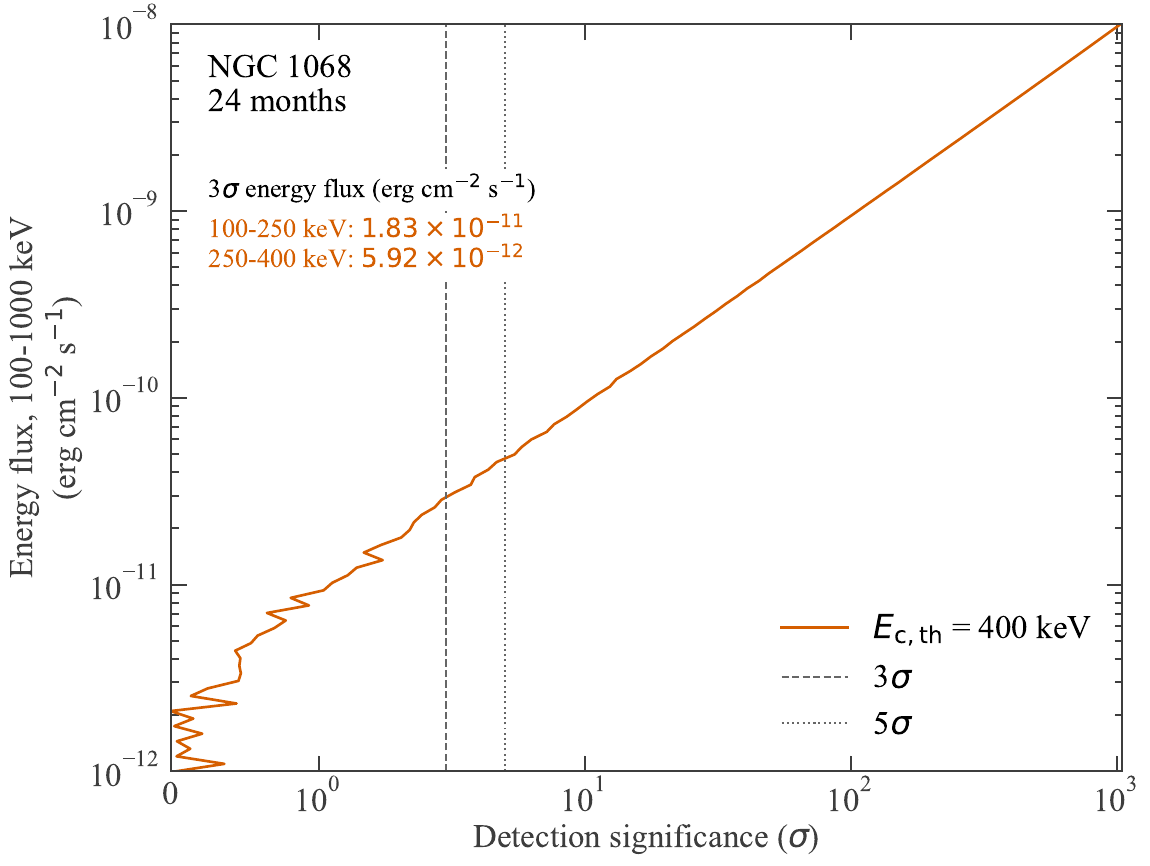

In [9]:
prepared_400 = prepare_cutoff_case(400.0)
case_400 = run_poisson_case(prepared_400)
fig_400, ax_400 = plot_cutoff_case(case_400)


## 8. Cutoff energy: 128 keV

Use the same exposure, background, flux grid, and fitting policy with a
128-keV cutoff. Independent random streams are used for this cutoff.


Cutoff: 128 keV; exposure: 24 months
Reference K at 200 keV: 4.7647e-06 ph cm^-2 s^-1 keV^-1
Measured-energy range: [  100. 10000.] keV
Positive-background cells: 202,155 / 230,400
Retained reference source counts: 208,304.342
Retained source fraction: 99.9991%
Background counts in the likelihood: 507,151,368
Asimov validation passed for the fitted likelihood.
Ec=128 keV: 10/100 flux points; 9.3 s elapsed
Ec=128 keV: 20/100 flux points; 19.2 s elapsed
Ec=128 keV: 30/100 flux points; 29.7 s elapsed
Ec=128 keV: 40/100 flux points; 40.5 s elapsed
Ec=128 keV: 50/100 flux points; 51.6 s elapsed
Ec=128 keV: 60/100 flux points; 63.3 s elapsed
Ec=128 keV: 70/100 flux points; 74.7 s elapsed
Ec=128 keV: 80/100 flux points; 86.0 s elapsed
Ec=128 keV: 90/100 flux points; 97.4 s elapsed
Ec=128 keV: 100/100 flux points; 108.9 s elapsed
Saved median-only CSV: /Users/parshadkp/Software/cosipy/docs/tutorials/source_injector/outputs/NGC1068_CPL128_Poisson/NGC1068_GTI_CPL_index_m2p1_Ec128_24months_band10

    energy_flux_erg_cm2_s            ts  significance_sigma
0            1.000000e-12  5.278200e-02            0.229743
1            1.097499e-12  5.646777e-04            0.023763
2            1.204504e-12  1.146448e-02            0.107072
3            1.321941e-12  5.080019e-02            0.225389
4            1.450829e-12  5.772698e-02            0.240264
..                    ...           ...                 ...
95           6.892612e-09  7.092593e+05          842.175329
96           7.564633e-09  8.498728e+05          921.885481
97           8.302176e-09  1.018617e+06         1009.265371
98           9.111628e-09  1.219136e+06         1104.144761
99           1.000000e-08  1.460271e+06         1208.416591

[100 rows x 3 columns]

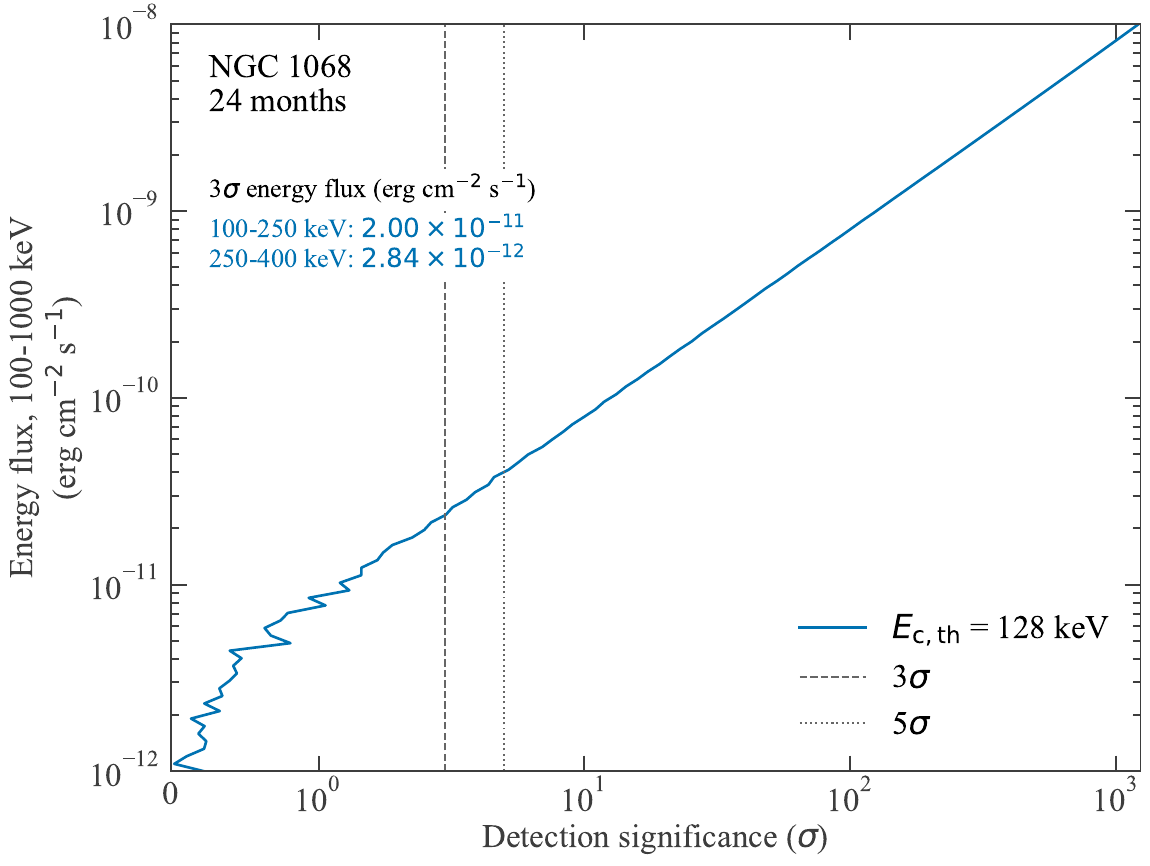

In [10]:
prepared_128 = prepare_cutoff_case(128.0)
case_128 = run_poisson_case(prepared_128)
fig_128, ax_128 = plot_cutoff_case(case_128)


## 9. Overlay the two median curves

Both curves show the median test statistic from the ensemble, converted to
nominal detection significance. The cutoff energies appear only in the legend.
The 3- and 5-sigma lines correspond to median TS values of 9 and 25.


Saved: /Users/parshadkp/Software/cosipy/docs/tutorials/source_injector/outputs/NGC1068_GTI_CPL_index_m2p1_Ec400_vs_Ec128_24months_band100_1000keV_Poisson_100flux_100realizations_median_TS_comparison.pdf
Total ensemble time: 214.5 s


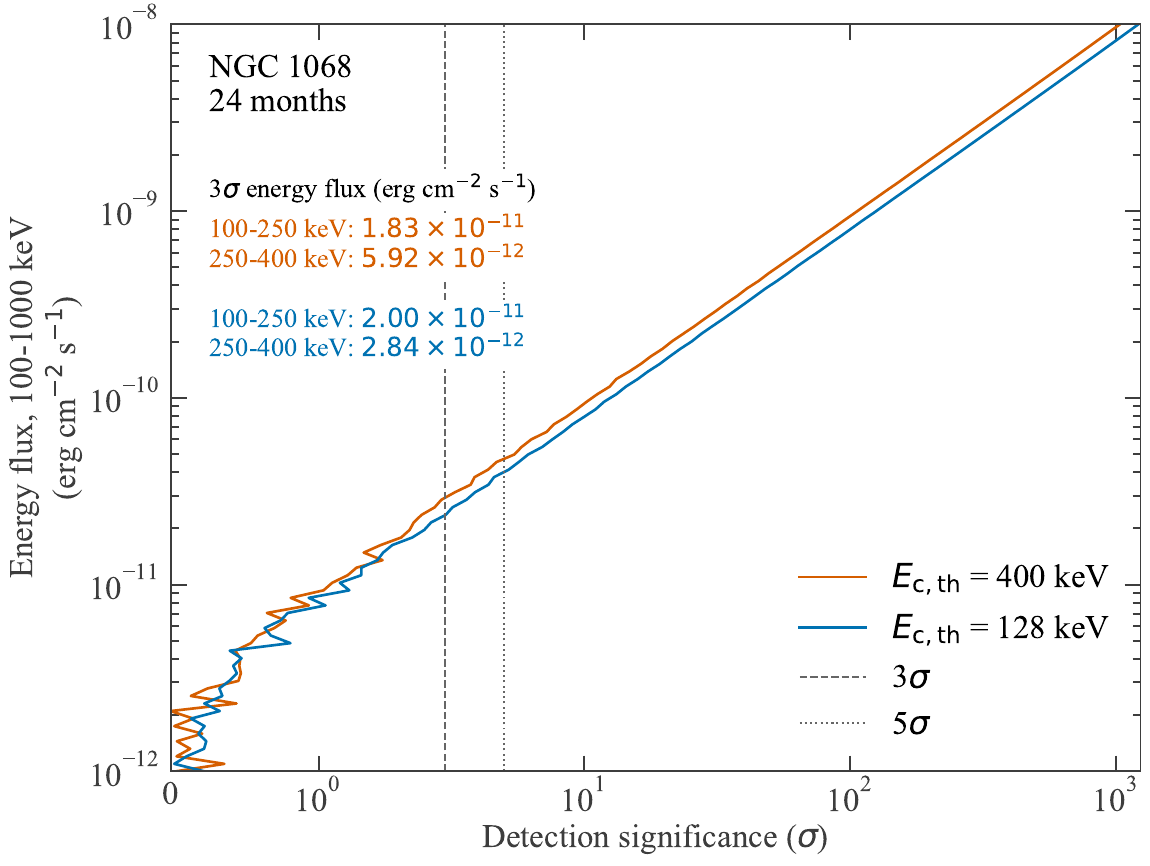

In [11]:
comparison_pdf_path = OUTPUT_ROOT / (
    f'NGC1068_GTI_CPL_index_{SPECTRAL_INDEX_TAG}_Ec400_vs_Ec128_'
    f'{EXPOSURE_MONTHS:g}months_{FLUX_BAND_TAG}_Poisson_{len(flux_values)}flux_'
    f'{N_REALIZATIONS}realizations_median_TS_comparison.pdf'
)
fig_comparison, ax_comparison = plot_cutoff_cases(
    [case_400, case_128], comparison_pdf_path,
)
print(f'Total ensemble time: {case_400["elapsed_s"] + case_128["elapsed_s"]:.1f} s')


## 10. Integrated photon flux

These additional figures use integrated photon flux over the same 100-1,000
keV band. For each fixed cutoff spectrum,

$$\Phi=\int_{100}^{1000}\frac{\mathrm{d}N}{\mathrm{d}E}\,\mathrm{d}E,
\qquad F_E=\int_{100}^{1000}E\frac{\mathrm{d}N}{\mathrm{d}E}\,\mathrm{d}E.$$

The conversion includes keV to erg. Each existing energy-flux point maps to a
photon-flux point for its spectrum, so the source expectation and TS are
unchanged. No new response convolution or Poisson ensemble is needed. The
photon-flux grid is spectrum dependent because the original grid was uniform
in log energy flux.

The photon-flux CSVs each contain 100 rows with only `photon_flux_ph_cm2_s` and
`ts`. The photon-flux figures retain detection significance on x and flux on y.
Their annotations show photon flux in 100-250 and 250-400 keV at the full-likelihood
3-sigma detection threshold. These are sub-band fluxes at that threshold,
not independent detection limits using only the sub-band events.


In [12]:
def add_photon_flux_output(case):
    """Convert the existing energy-flux grid and export photon flux with TS."""
    cutoff_keV = float(case['cutoff_keV'])

    def shape(energy_keV):
        return (energy_keV / PIVOT_KEV)**SPECTRAL_INDEX * np.exp(-energy_keV / cutoff_keV)

    photon_integral = quad(shape, *FLUX_BAND_KEV, epsabs=0.0, epsrel=1e-10)[0]
    energy_integral = quad(
        lambda energy: energy * shape(energy), *FLUX_BAND_KEV,
        epsabs=0.0, epsrel=1e-10,
    )[0] * u.keV.to(u.erg)
    photons_per_erg = photon_integral / energy_integral
    frame = case['results'].copy()
    frame['photon_flux_ph_cm2_s'] = frame['energy_flux_erg_cm2_s'] * photons_per_erg
    photon_csv_path = case['csv_path'].with_name(case['csv_path'].stem + '_photon_flux.csv')
    photon_pdf_path = case['pdf_path'].with_name(case['pdf_path'].stem + '_photon_flux.pdf')
    frame[['photon_flux_ph_cm2_s', 'ts']].to_csv(
        photon_csv_path, index=False, float_format='%.12g',
    )
    print('Saved:', photon_csv_path)
    return {
        **case, 'results': frame, 'photon_csv_path': photon_csv_path,
        'photon_pdf_path': photon_pdf_path, 'photons_per_erg': photons_per_erg,
    }


### Photon flux: 400 keV cutoff


Saved: /Users/parshadkp/Software/cosipy/docs/tutorials/source_injector/outputs/NGC1068_CPL400_Poisson/NGC1068_GTI_CPL_index_m2p1_Ec400_24months_band100_1000keV_Poisson_100flux_100realizations_eeb658a3fd_median_TS_photon_flux.csv
Saved: /Users/parshadkp/Software/cosipy/docs/tutorials/source_injector/outputs/NGC1068_CPL400_Poisson/NGC1068_GTI_CPL_index_m2p1_Ec400_24months_band100_1000keV_Poisson_100flux_100realizations_eeb658a3fd_median_TS_photon_flux.pdf


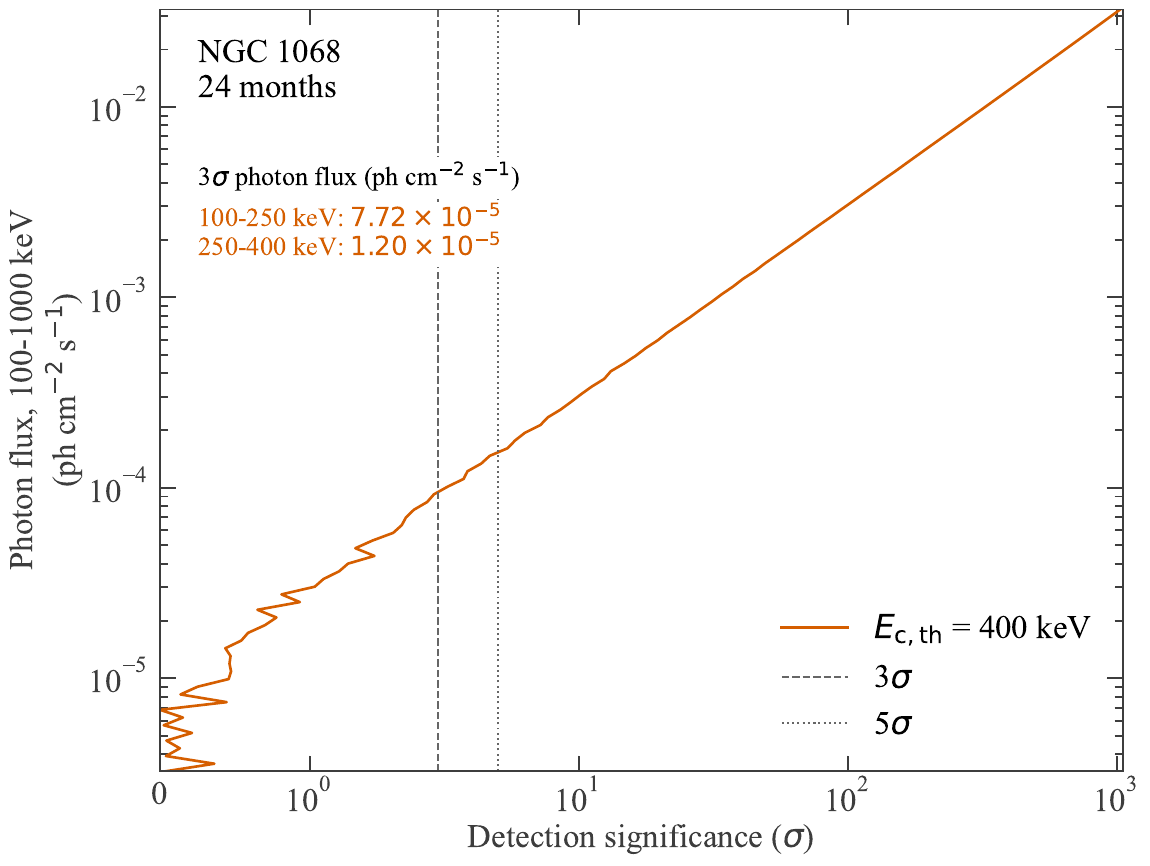

In [13]:
photon_case_400 = add_photon_flux_output(case_400)
fig_photon_400, ax_photon_400 = plot_cutoff_cases(
    [photon_case_400], photon_case_400['photon_pdf_path'], flux_kind='photon',
)


### Photon flux: 128 keV cutoff


Saved: /Users/parshadkp/Software/cosipy/docs/tutorials/source_injector/outputs/NGC1068_CPL128_Poisson/NGC1068_GTI_CPL_index_m2p1_Ec128_24months_band100_1000keV_Poisson_100flux_100realizations_46dcd55b45_median_TS_photon_flux.csv
Saved: /Users/parshadkp/Software/cosipy/docs/tutorials/source_injector/outputs/NGC1068_CPL128_Poisson/NGC1068_GTI_CPL_index_m2p1_Ec128_24months_band100_1000keV_Poisson_100flux_100realizations_46dcd55b45_median_TS_photon_flux.pdf


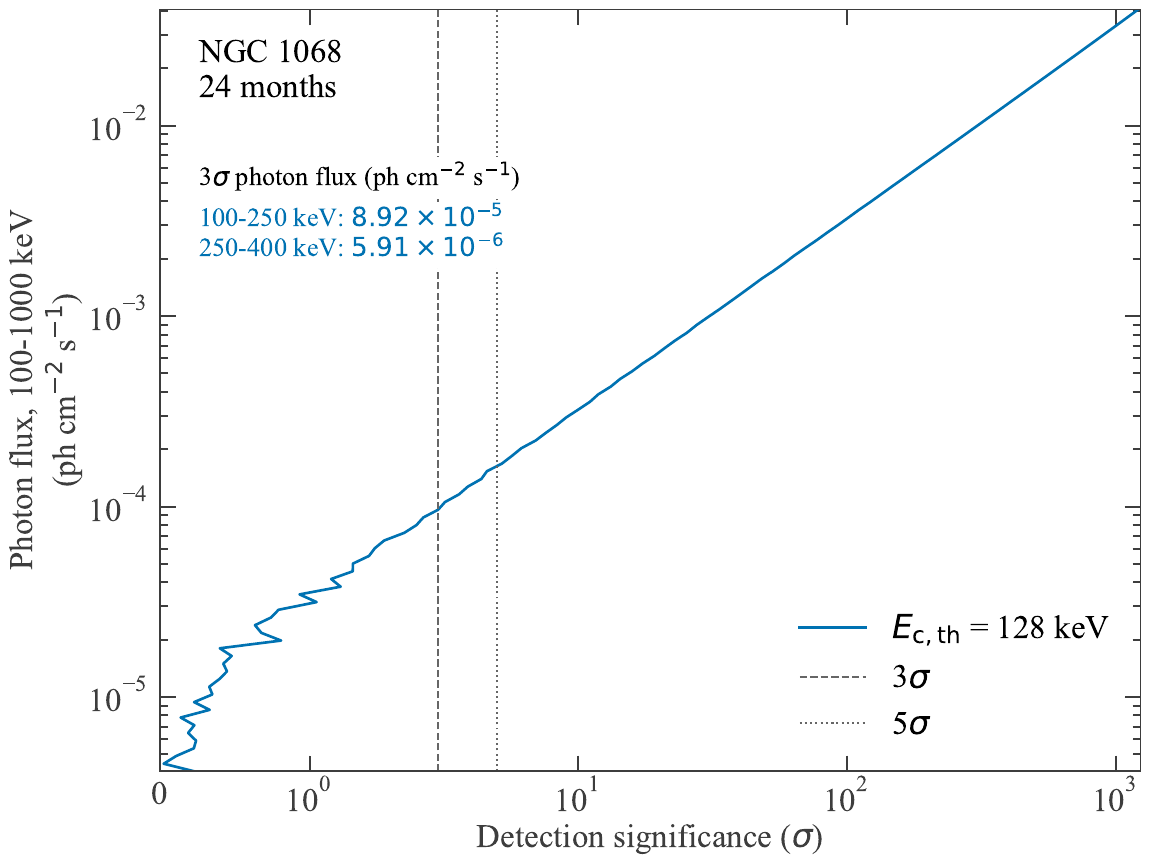

In [14]:
photon_case_128 = add_photon_flux_output(case_128)
fig_photon_128, ax_photon_128 = plot_cutoff_cases(
    [photon_case_128], photon_case_128['photon_pdf_path'], flux_kind='photon',
)


### Photon flux: cutoff comparison


Saved: /Users/parshadkp/Software/cosipy/docs/tutorials/source_injector/outputs/NGC1068_GTI_CPL_index_m2p1_Ec400_vs_Ec128_24months_band100_1000keV_Poisson_100flux_100realizations_median_TS_comparison_photon_flux.pdf


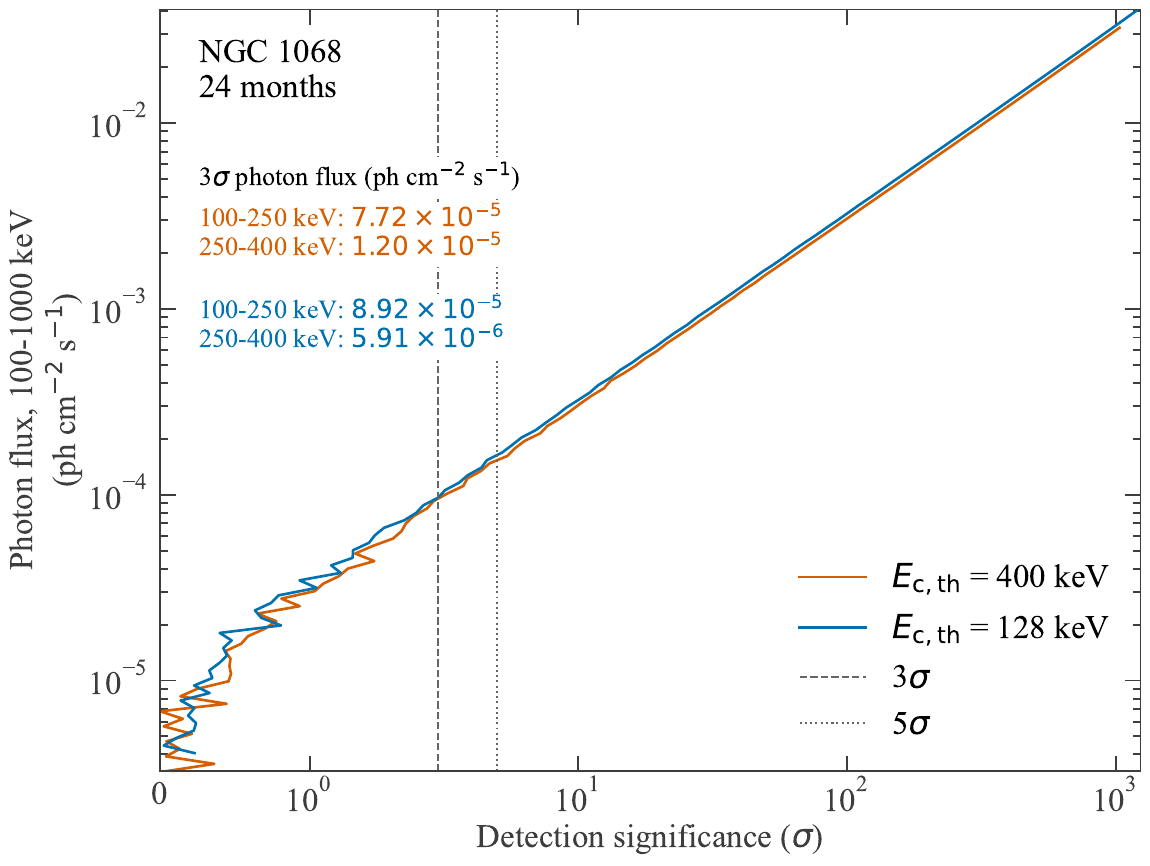

In [15]:
photon_comparison_pdf_path = comparison_pdf_path.with_name(
    comparison_pdf_path.stem + '_photon_flux.pdf'
)
fig_photon_comparison, ax_photon_comparison = plot_cutoff_cases(
    [photon_case_400, photon_case_128], photon_comparison_pdf_path,
    flux_kind='photon',
)


## Interpretation

The CSV `ts` value is the sample median of 100 fitted realization TS values at
that injected flux. It is not a single selected realization or an Asimov TS.
The displayed significance is the square root of that median. This differs
slightly from taking the sample median of the square roots when an even number
of realizations is used.

A median crossing of 3 sigma describes roughly 50% detection probability under
the stated fixed-shape model. It does not imply that 90% of realizations exceed
3 sigma. This initial run is intended to estimate the median curve; increasing
`N_REALIZATIONS` improves its Monte Carlo precision.

These remain binned forecasts conditional on the supplied DC4 response and
background model. Poisson sampling adds counting fluctuations but does not
remove response-binning or background-model systematics.
